# UMUD: от УЗИ-кадра к PA, FL, MT

Конвейер в четыре шага:

1. **Масштаб.** Находим на кадре УЗ-область и px/см по рискам шкалы (`umud_scale.py`).
2. **Сегментация.** Две UNet: апоневрозы (2 канала: поверхностный и глубокий) и фасцикулы.
3. **Геометрия.** Внутренние края апоневрозов → MT; ориентация волокон (structure tensor с весом от сети) → PA; продление фасцикулы → FL.
4. **Калибровка** на 35 снимках экспертного бенчмарка UMUD, затем сабмит.

Вся геометрия считается на метрической сетке: кадр пересэмплирован так, что 1 мм = `CFG.px_per_mm` пикселей.
Поэтому пороги и размеры окон в коде заданы в миллиметрах.

Флаги в `CFG`: `folds` (какие фолды учить; уже обученные берутся из `work/`), `retrain` (переучить заново), `smoke` (быстрый прогон на крошечной выборке, переменная окружения `UMUD_SMOKE=1`).

The rules of the competition do not allow publishing its images, so this notebook displays only the public UMUD benchmark. Competition data have to be downloaded from Kaggle, see the README.

In [1]:
import hashlib
import json
import os
import pickle
import time
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import segmentation_models_pytorch as smp
import torch
import torch.nn.functional as F
from PIL import Image
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import GroupKFold

from umud_aspect import orientation_pa, predict_tiles
from umud_manual import measure_manual
from umud_scale import decode_scale, layout_name

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data/raw"
BENCH = ROOT / "external/osf_umud/benchmark_dataset_architecture_v0.1.0/benchmark_dataset_architecture_v0.1.0"
SMOKE = os.environ.get("UMUD_SMOKE") == "1"
WORK = ROOT / ("work_smoke" if SMOKE else "work")   # weights, caches, submission
WORK.mkdir(exist_ok=True)
CFG = dict(
    smoke=SMOKE,
    retrain=False,          # True: учить заново, даже если веса фолда уже лежат в work/
    folds=[0, 1, 2, 3, 4],  # какие фолды учить; инференс усредняет все найденные
    n_folds=5,
    img_size=256 if SMOKE else 512,
    encoder="tu-convnext_tiny",
    epochs={"apo": 1 if SMOKE else 40, "fasc": 1 if SMOKE else 20},  # фасцикулы переобучаются после ~15 эпох
    batch=8,
    lr=3e-4,
    vram_fraction=0.6,      # потолок VRAM, чтобы карта оставалась свободной
    px_per_mm=8.0,          # разрешение метрической сетки для геометрии
    pa_method="segments",   # "segments": по отдельным фрагментам фасцикул; "tensor": structure tensor по карте;
                            #   "orient": по полю направлений, если сеть фасцикул его выдаёт (v9); "mean": среднее segments и orient
    pa_offset=1.68,         # ручная поправка поверх калибровки по бенчмарку (та добавляет +0.32), итог +2.0°.
                            #   Итоговый сдвиг по LB: 0 -> 0.529, +2 -> 0.480, +4 -> 0.610
    fl_scale=1.0,           # их и h_over_v можно проверять на публичном LB
    # Горизонтальная поправка масштаба по раскладке кадра: x_mm = x_px / (px_per_mm_vertical * h_over_v).
    # 1.0 = квадратные пиксели, как велит хост. У telemed_left_ruler нижние риски дают 0.905.
    h_over_v={"telemed_left_ruler": 1.0},
    seed=0,
    # Обучаемая геометрия (раздел 10): поправка к числам по ручной разметке теста из annotations/.
    # label_shift переводит манеру разметчика в манеру хостов, оценено по 8 сабмитам с известным LB.
    # Сети фасцикул v9 (scripts/train_v9.py): вход без искажения пропорций, голова направления, ConvNeXt и
    # EfficientNet-B4. "mix": карта фасцикул = среднее квадратной сети и двух сетей v9 (LB 0.383),
    # "ens": только сети v9, None: без них (v5, LB 0.385). Апоневрозы всегда от квадратной сети: нарезка
    # на квадраты их портит, в куске высокого кадра часто виден только один апоневроз.
    v9="mix",
    learned=dict(enabled=True, label_dir="annotations", label_shift={"pa": 0.75, "fl": 1.04, "mt": 0.97},
                 n_splits=5, seeds=5),
)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
if DEVICE == "cuda":
    torch.cuda.set_per_process_memory_fraction(CFG["vram_fraction"])
print(DEVICE, torch.__version__, "| smoke" if SMOKE else "")

.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


cuda 2.8.0+cu128 


## 1. Чтение кадров и поиск УЗ-области

Маски читаем через `convert("L")`: у палитровых масок индекс 0 означает белый цвет, и после конвертации оба формата дают одинаковую картинку.

Для тестовых кадров рамку УЗ-области даёт декодер шкалы. Для трейна и бенчмарка её ищет `find_roi`: самая большая область со спекл-текстурой. Плоские панели интерфейса и редкий текст в неё не попадают.

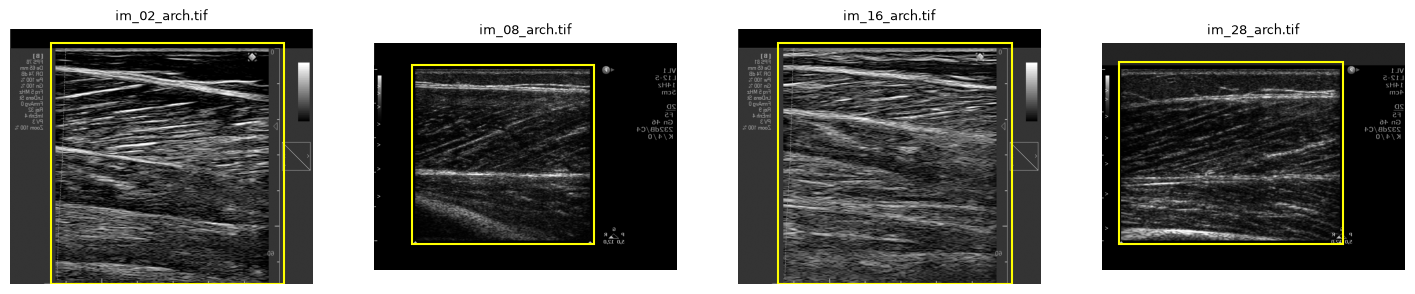

In [2]:
def read_gray(path) -> np.ndarray:
    return np.asarray(Image.open(path).convert("L"))


def read_mask(path) -> np.ndarray:
    return np.asarray(Image.open(path).convert("L")) > 127


def longest_run(flags: np.ndarray):
    """(start, stop) of the longest run of True values."""
    best, start = (0, 0), None
    for i, f in enumerate(list(flags) + [False]):
        if f and start is None:
            start = i
        if not f and start is not None:
            if i - start > best[1] - best[0]:
                best = (start, i)
            start = None
    return best if best[1] > best[0] else (0, len(flags))


def find_roi(g: np.ndarray):
    """(left, top, right, bottom) of the ultrasound image inside a screenshot.

    Speckle texture fills most of every column and row of the ultrasound image,
    while UI text and ruler ticks fill only a small part of theirs.
    """
    s = 4
    f = cv2.resize(g, (g.shape[1] // s, g.shape[0] // s), interpolation=cv2.INTER_AREA).astype(np.float32)
    std = np.sqrt(np.clip(cv2.blur(f * f, (5, 5)) - cv2.blur(f, (5, 5)) ** 2, 0, None))
    textured = cv2.blur((std > 3).astype(np.float32), (5, 5)) > 0.5
    c0, c1 = longest_run(textured.mean(axis=0) > 0.5)
    r0, r1 = longest_run(textured[:, c0:c1].mean(axis=1) > 0.5)
    return c0 * s, r0 * s, c1 * s, r1 * s


fig, axes = plt.subplots(1, 4, figsize=(18, 3.5))
examples = [BENCH / f"im_{i:02d}_arch.tif" for i in (2, 8, 16, 28)]
for ax, p in zip(axes, examples):
    g = read_gray(p)
    l, t, r, b = find_roi(g)
    ax.imshow(g, cmap="gray")
    ax.add_patch(plt.Rectangle((l, t), r - l, b - t, fill=False, ec="yellow", lw=1.5))
    ax.set_title(p.name, fontsize=9)
    ax.axis("off")
plt.show()

## 2. Масштаб тестовых кадров

`decode_scale` читает риски вертикальной шкалы глубины. Две проверки:
- глубина УЗ-области должна быть кратна 0.5 см (так её выставляют на аппарате);
- там, где есть и нижние риски, сравниваем горизонтальный масштаб с вертикальным.

На раскладке `telemed_left_ruler` (90 кадров) нижние риски идут через 134–135 px при 148.2 px/см по вертикали, то есть горизонталь сжата в 0.905 раза. Хост пишет, что пиксели квадратные и мерить надо по вертикали. Если разметчики мерили в ImageJ с одним масштабом, правильный режим `1.0`. Иначе — `0.905`. Это переключатель `CFG["h_over_v"]`, проверять его на публичном LB.

In [3]:
def test_meta() -> pd.DataFrame:
    rows = []
    for p in sorted((DATA / "test_images_v2/test_set_v2").iterdir()):
        a = np.asarray(Image.open(p))
        ft = p.suffix[1:].lower()
        px_cm, (l, t, r, b) = decode_scale(a, ft)
        rows.append(dict(image_id=p.name, path=str(p), layout=layout_name(a, ft), px_per_cm=px_cm,
                         l=l, t=t, r=r, b=b, depth_cm=(b - t) / px_cm, width_cm=(r - l) / px_cm))
    return pd.DataFrame(rows)


meta = test_meta()
meta["depth_off_mm"] = 10 * (meta.depth_cm - (meta.depth_cm * 2).round() / 2).abs()
print(meta.groupby("layout").agg(n=("image_id", "size"), px_cm_min=("px_per_cm", "min"),
                                 px_cm_max=("px_per_cm", "max"), depth_off_max_mm=("depth_off_mm", "max"),
                                 width_cm=("width_cm", "median")).round(2))


def bottom_tick_period(g: np.ndarray):
    """Median spacing of bright tick marks along the bottom 40 rows, or None."""
    best = None
    for y0 in range(g.shape[0] - 40, g.shape[0] - 2):
        on = g[y0:y0 + 3].max(axis=0) > 90
        xs = np.flatnonzero(np.diff(on.astype(int)) == 1)
        if len(xs) >= 4 and np.diff(xs).std() < 2.5 and (best is None or len(xs) > len(best)):
            best = xs
    return None if best is None else float(np.median(np.diff(best)))


for layout, grp in meta.groupby("layout"):
    r = grp.iloc[0]
    per = bottom_tick_period(read_gray(r.path))
    ratio = "нет нижних рисок" if per is None else f"h/v = {per / r.px_per_cm:.3f}"
    print(f"{layout:22s} {r.image_id}: вертикаль {r.px_per_cm:.1f} px/см, {ratio}")

                      n  px_cm_min  px_cm_max  depth_off_max_mm  width_cm
layout                                                                   
bottom_ruler_513      8       77.8      77.80              0.48      5.98
bottom_ruler_853     12      166.8     166.80              1.14      6.41
lumify               58      100.0     201.00              0.50      2.86
siemens_right_ruler  91       87.0     159.67              0.46      5.74
telemed_644          50      126.1     126.10              0.99      6.40
telemed_left_ruler   90      148.2     148.20              1.01      5.79
bottom_ruler_513       IMG_00040.tif: вертикаль 77.8 px/см, нет нижних рисок
bottom_ruler_853       IMG_00036.tif: вертикаль 166.8 px/см, нет нижних рисок
lumify                 IMG_00252.png: вертикаль 150.0 px/см, нет нижних рисок
siemens_right_ruler    IMG_00001.tif: вертикаль 135.3 px/см, нет нижних рисок
telemed_644            IMG_00056.tif: вертикаль 126.1 px/см, h/v = 0.999
telemed_left_ruler     I

## 3. Обучающая выборка

Что чиним при сборке:
- **дубли**: 670 одинаковых пар в фасцикулах выкидываем по хэшу снимка;
- **пропорции**: часть снимков растянута до 800×1200, а маска осталась в исходном размере. Тогда возвращаем снимку размер маски. Исключение — маски 864×1152: это кадры Siemens, у которых родной размер как раз 800×1200 (такие же кадры в тесте);
- **группы для фолдов**: соседние кадры одного видео почти одинаковы, поэтому объединяем их в группу, чтобы они не попали одновременно в трейн и валидацию;
- **каналы апоневрозов**: в каждой колонке первая сверху полоса маски — поверхностный апоневроз, вторая — глубокий, остальные (например, у TA их три) отбрасываем.

Готовые массивы кешируются в `work/cache_*.npz`.

In [4]:
def split_apo(mask: np.ndarray) -> np.ndarray:
    """(2, H, W): top band = superficial, second band = deep aponeurosis, per column."""
    n, lab, st, _ = cv2.connectedComponentsWithStats(mask.astype(np.uint8))
    mask = np.isin(lab, np.flatnonzero(st[:, 4] >= 200)[1:])  # drop specks
    out = np.zeros((2, *mask.shape), bool)
    for x in np.flatnonzero(mask.any(axis=0)):
        ys = np.flatnonzero(mask[:, x])
        runs = np.split(ys, np.flatnonzero(np.diff(ys) > 1) + 1)
        for ch, run in enumerate(runs[:2]):
            out[ch, run, x] = True
    return out


def frame_groups(images) -> list:
    """Consecutive near-identical frames (same video) get the same group id."""
    gid, prev, out = 0, None, []
    for g in images:
        thumb = cv2.resize(g, (48, 48), interpolation=cv2.INTER_AREA).astype(np.float32)
        if prev is None or np.abs(thumb - prev).mean() > 8:
            gid += 1
        out.append(gid)
        prev = thumb
    return out


def build_cache(task: str):
    path = WORK / f"cache_{task}_{CFG['img_size']}.npz"
    if path.exists():
        d = np.load(path)
        return d["x"], d["y"], d["groups"]
    S = CFG["img_size"]
    img_dir = DATA / f"{task}_imgs_v1/{task}_images_new_model_v1"
    msk_dir = DATA / f"{task}_masks_v1/{task}_masks_new_model_v1"
    files = sorted(img_dir.glob("*.tif"))
    if SMOKE:
        files = files[:: len(files) // 48]
    xs, ys, rois, seen = [], [], [], set()
    for p in files:
        h = hashlib.md5(p.read_bytes()).hexdigest()
        if h in seen:
            continue
        seen.add(h)
        g, m = read_gray(p), read_mask(msk_dir / p.name)
        if g.shape != m.shape:
            if m.shape == (864, 1152):
                m = cv2.resize(m.astype(np.uint8), g.shape[::-1], interpolation=cv2.INTER_NEAREST) > 0
            else:
                g = cv2.resize(g, m.shape[::-1], interpolation=cv2.INTER_AREA)
        l, t, r, b = find_roi(g)
        g, m = g[t:b, l:r], m[t:b, l:r]
        target = split_apo(m) if task == "apo" else m[None]
        thr = 0.5 if task == "apo" else 0.1  # keep thin fascicle lines alive after downsizing
        xs.append(cv2.resize(g, (S, S), interpolation=cv2.INTER_AREA))
        ys.append(np.stack([cv2.resize(c.astype(np.float32), (S, S), interpolation=cv2.INTER_AREA) > thr
                            for c in target]))
    x, y = np.stack(xs), np.stack(ys).astype(np.uint8)
    groups = np.array(frame_groups(xs))
    np.savez(path, x=x, y=y, groups=groups)
    return x, y, groups


t0 = time.time()
cache = {task: build_cache(task) for task in ["apo", "fasc"]}
for task, (x, y, g) in cache.items():
    print(f"{task}: {len(x)} уникальных снимков, {len(set(g))} групп, доля пикселей маски {y.mean():.3%}")
print(f"{time.time() - t0:.0f} c")

apo: 1029 уникальных снимков, 983 групп, доля пикселей маски 2.372%


fasc: 2091 уникальных снимков, 1121 групп, доля пикселей маски 1.033%
3 c


In [5]:
# Training images are competition data: they are not displayed here, so that outputs can be published.

## 4. Датасет и аугментации

Аугментации под УЗИ: отражение по горизонтали, одно аффинное преобразование (поворот ±8°, зум, сдвиг и небольшое растяжение по горизонтали — у аппаратов разная анизотропия), гамма и усиление, блюр, мультипликативный шум как грубая имитация спекла.

In [6]:
def augment(x: np.ndarray, y: np.ndarray, rng):
    S = x.shape[0]
    if rng.random() < 0.5:
        x, y = x[:, ::-1], y[:, :, ::-1]
    th = np.radians(rng.uniform(-8, 8))
    zoom, stretch = rng.uniform(0.85, 1.2), rng.uniform(0.9, 1.1)
    A = np.array([[np.cos(th), -np.sin(th)], [np.sin(th), np.cos(th)]]) @ np.diag([zoom * stretch, zoom])
    c = np.array([S / 2, S / 2])
    t = c + rng.uniform(-0.05, 0.05, 2) * S - A @ c
    M = np.hstack([A, t[:, None]]).astype(np.float32)
    x = cv2.warpAffine(np.ascontiguousarray(x), M, (S, S), flags=cv2.INTER_LINEAR)
    y = np.stack([cv2.warpAffine(np.ascontiguousarray(ch), M, (S, S), flags=cv2.INTER_NEAREST) for ch in y])
    f = x.astype(np.float32) / 255
    f = np.clip(f ** rng.uniform(0.7, 1.5) * rng.uniform(0.8, 1.25), 0, 1)
    if rng.random() < 0.3:
        f = cv2.GaussianBlur(f, (0, 0), rng.uniform(0.5, 1.2))
    f = f * rng.normal(1, rng.uniform(0, 0.15), f.shape).astype(np.float32)
    return np.clip(f, 0, 1), y


class SegDataset(torch.utils.data.Dataset):
    def __init__(self, x, y, idx, train: bool):
        self.x, self.y, self.idx, self.train = x, y, idx, train
        self.rng = np.random.default_rng(CFG["seed"])

    def __len__(self):
        return len(self.idx)

    def __getitem__(self, i):
        x, y = self.x[self.idx[i]], self.y[self.idx[i]]
        if self.train:
            x, y = augment(x, y, self.rng)
        else:
            x = x.astype(np.float32) / 255
        return torch.from_numpy(np.ascontiguousarray(x))[None], torch.from_numpy(np.ascontiguousarray(y)).float()


## 5. Модель и обучение

UNet из `segmentation_models_pytorch` с энкодером ConvNeXt-Tiny (веса ImageNet), вход — один серый канал. Лосс BCE + Dice, AdamW, OneCycle, смешанная точность bf16. Лучшая эпоха по Dice на валидационном фолде сохраняется в `work/{task}_fold{k}.pt`.

In [7]:
def make_model(n_classes: int, pretrained=True):
    return smp.Unet(CFG["encoder"], encoder_weights="imagenet" if pretrained else None,
                    in_channels=1, classes=n_classes)


def dice_loss(logits, y, eps=1.0):
    p = torch.sigmoid(logits)
    inter = (p * y).sum((0, 2, 3))
    return 1 - ((2 * inter + eps) / (p.sum((0, 2, 3)) + y.sum((0, 2, 3)) + eps)).mean()


@torch.no_grad()
def dice_score(logits, y):
    p = (logits > 0).float()
    inter = (p * y).sum((0, 2, 3))
    return ((2 * inter + 1) / (p.sum((0, 2, 3)) + y.sum((0, 2, 3)) + 1)).cpu().numpy()


def train_fold(task: str, fold: int):
    x, y, groups = cache[task]
    tr, va = list(GroupKFold(CFG["n_folds"]).split(x, groups=groups))[fold]
    dl_tr = torch.utils.data.DataLoader(SegDataset(x, y, tr, True), CFG["batch"], shuffle=True, drop_last=True)
    dl_va = torch.utils.data.DataLoader(SegDataset(x, y, va, False), CFG["batch"])
    model = make_model(y.shape[1]).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=CFG["lr"], weight_decay=1e-4)
    epochs = CFG["epochs"][task]
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, CFG["lr"], total_steps=epochs * len(dl_tr), pct_start=0.1)
    best, path = -1.0, WORK / f"{task}_fold{fold}.pt"
    for ep in range(epochs):
        t0, losses = time.time(), []
        model.train()
        for xb, yb in dl_tr:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            with torch.autocast(DEVICE, dtype=torch.bfloat16, enabled=DEVICE == "cuda"):
                logits = model(xb)
            logits = logits.float()
            loss = F.binary_cross_entropy_with_logits(logits, yb) + dice_loss(logits, yb)
            opt.zero_grad()
            loss.backward()
            opt.step()
            sched.step()
            losses.append(loss.item())
        model.eval()
        dices = []
        with torch.no_grad():
            for xb, yb in dl_va:
                with torch.autocast(DEVICE, dtype=torch.bfloat16, enabled=DEVICE == "cuda"):
                    logits = model(xb.to(DEVICE)).float()
                dices.append(dice_score(logits, yb.to(DEVICE)))
        dice = np.mean(dices, axis=0)
        if dice.mean() > best:
            best = dice.mean()
            torch.save(model.state_dict(), path)
        print(f"{task} fold{fold} ep{ep:02d} loss {np.mean(losses):.3f} val dice {np.round(dice, 3)} "
              f"{'*' if best == dice.mean() else ' '} {time.time() - t0:.0f}s")
    return best


for task in ["apo", "fasc"]:
    for fold in CFG["folds"]:
        if CFG["retrain"] or not (WORK / f"{task}_fold{fold}.pt").exists():
            train_fold(task, fold)
        else:
            print(f"{task} fold{fold}: веса уже есть, пропускаю")

apo fold0: веса уже есть, пропускаю
apo fold1: веса уже есть, пропускаю
apo fold2: веса уже есть, пропускаю
apo fold3: веса уже есть, пропускаю
apo fold4: веса уже есть, пропускаю
fasc fold0: веса уже есть, пропускаю
fasc fold1: веса уже есть, пропускаю
fasc fold2: веса уже есть, пропускаю
fasc fold3: веса уже есть, пропускаю
fasc fold4: веса уже есть, пропускаю


## 6. Предсказание масок

Усредняем все найденные фолды и отражение по горизонтали (TTA). На выходе вероятности в размере входного кадра.

In [8]:
def load_models(task: str):
    n = 2 if task == "apo" else 1
    models = []
    for p in sorted(WORK.glob(f"{task}_fold*.pt")):
        m = make_model(n, pretrained=False)
        m.load_state_dict(torch.load(p, map_location="cpu"))
        models.append(m.to(DEVICE).eval())
    return models


@torch.no_grad()
def predict_probs(models, g: np.ndarray) -> np.ndarray:
    S = CFG["img_size"]
    x = torch.from_numpy(cv2.resize(g, (S, S), interpolation=cv2.INTER_AREA).astype(np.float32) / 255)
    x = x[None, None].to(DEVICE)
    acc = 0
    for m in models:
        with torch.autocast(DEVICE, dtype=torch.bfloat16, enabled=DEVICE == "cuda"):
            acc = acc + torch.sigmoid(m(x).float()) + torch.sigmoid(m(x.flip(-1)).float()).flip(-1)
    p = (acc / (2 * len(models)))[0].cpu().numpy()
    return np.stack([cv2.resize(c, g.shape[::-1], interpolation=cv2.INTER_LINEAR) for c in p])


V9_RUNS = {"fasc_cnx": ("tu-convnext_tiny", 3), "fasc_eff": ("efficientnet-b4", 3)}


def load_v9():
    """Aspect-preserving fascicle networks with the direction head, if trained (scripts/train_v9.py)."""
    out = {}
    for name, (enc, classes) in V9_RUNS.items():
        out[name] = []
        for p in sorted((WORK / "v9").glob(f"{name}_fold*.pt")):
            m = smp.Unet(enc, encoder_weights=None, in_channels=1, classes=classes)
            m.load_state_dict(torch.load(p, map_location="cpu"))
            out[name].append(m.to(DEVICE).eval())
    return out if CFG["v9"] and all(out.values()) else {}


MODELS = {task: load_models(task) for task in ["apo", "fasc"]}
V9 = load_v9()
print({k: len(v) for k, v in MODELS.items()}, "моделей загружено")

{'apo': 5, 'fasc': 5} моделей загружено


## 7. Геометрия

Всё в миллиметрах на метрической сетке (`CFG.px_per_mm` пикселей на мм).

- **Апоневрозы** → прямые `y = a·x + b` по внутренним краям: нижний край поверхностного, верхний край глубокого. Так меряют эксперты, и MT по краям точнее, чем по осевым линиям.
- **Две мышцы в кадре** → если в канале глубокого апоневроза несколько полос, берём самую верхнюю, под которой почти нет фасцикул (меньше 15 % от всех). Так меряют хосты: при трёх апоневрозах только верхняя мышца. Фасцикулы под выбранной линией обнуляем. На бенчмарке не срабатывает ни разу, на тесте исправляет серию IMG_00071–75 (MT 33.5 → 17.6 мм).
- **MT** → перпендикуляр от поверхностного апоневроза к глубокому на 25, 50 и 75 % ширины, среднее.
- **Ориентация волокон** → structure tensor по карте вероятности фасцикул, вес пикселя = когерентность × вероятность². По сырому снимку считать нельзя: спекл в УЗИ вытянут вбок и тянет угол к горизонтали (на бенчмарке это давало PA на 4.9° ниже экспертов). Края у апоневрозов (12 % толщины) исключаем.
- **PA** (`CFG.pa_method = "segments"`) → каждый вытянутый фрагмент карты фасцикул длиннее 3 мм аппроксимируем отрезком (главная ось пикселей), берём его угол к глубокому апоневрозу, итог — медиана, взвешенная по длине. Так ближе к экспертам, которые меряют по отдельным чётким волокнам. Запасной вариант `"tensor"` — средняя ориентация в нижней трети мышцы. На бенчмарке: segments 0.253, tensor 0.270.
- **FL** → две оценки: `fl_line` — прямая со средней ориентацией волокон из центральной точки глубокого апоневроза до пересечения с поверхностным; `fl_trig = MT / sin(PA)`. Итог — взвешенное среднее, вес подбирается при калибровке. На бенчмарке `fl_trig` почти без смещения, а `fl_line` завышает FL на ~15 мм.
- **fl_frag** → каждый фрагмент продлеваем до обоих апоневрозов, итог — взвешенная медиана длин, вес больше у длинных фрагментов, которые меньше надо продлевать. Пока только считается: на бенчмарке не лучше смеси выше, решать будем по ручной разметке теста.


In [9]:
def to_metric(g: np.ndarray, probs: np.ndarray, px_per_mm_v: float, h_over_v: float = 1.0):
    """Resample image + probability maps so that 1 mm = CFG px_per_mm pixels on both axes."""
    k = CFG["px_per_mm"]
    fx, fy = k / (px_per_mm_v * h_over_v), k / px_per_mm_v
    size = (max(8, round(g.shape[1] * fx)), max(8, round(g.shape[0] * fy)))
    gm = cv2.resize(g, size, interpolation=cv2.INTER_AREA)
    pm = np.stack([cv2.resize(p, size, interpolation=cv2.INTER_LINEAR) for p in probs])
    return gm, pm


def edge_line(m: np.ndarray, edge: str):
    """Line y = a*x + b through the lower or upper edge of a binary band, robust to stray columns."""
    xs = np.flatnonzero(m.any(axis=0))
    ys = np.array([np.flatnonzero(m[:, x])[-1 if edge == "lower" else 0] for x in xs])
    a, b = np.polyfit(xs, ys, 1)
    res = np.abs(ys - (a * xs + b))
    keep = res <= 3 * np.median(res) + 1
    return tuple(np.polyfit(xs[keep], ys[keep], 1))


def fit_edge_line(prob: np.ndarray, edge: str):
    """Line through the inner edge ('lower' or 'upper') of an aponeurosis band."""
    m = (prob > 0.5).astype(np.uint8)
    n, lab, st, _ = cv2.connectedComponentsWithStats(m)
    if n < 2:
        return None
    big = np.flatnonzero(st[1:, 4] >= 0.2 * st[1:, 4].max()) + 1
    m = np.isin(lab, big)
    if m.any(axis=0).sum() < 0.15 * m.shape[1]:
        return None
    return edge_line(m, edge)


def deep_candidates(prob: np.ndarray, thr=0.25, min_span=0.3):
    """Upper-edge line of every band of the deep channel, top to bottom. Weak bands break into
    pieces, so pieces are joined along the horizontal before labelling."""
    k = CFG["px_per_mm"]
    m0 = (prob > thr).astype(np.uint8)
    joined = cv2.morphologyEx(m0, cv2.MORPH_CLOSE, np.ones((3, int(10 * k)), np.uint8))
    n, lab, st, _ = cv2.connectedComponentsWithStats(joined)
    bands = []
    for i in range(1, n):
        if st[i, 2] >= min_span * prob.shape[1]:
            m = (lab == i) & (m0 > 0)
            bands.append((np.nonzero(m)[0].mean(), edge_line(m, "upper")))
    return [line for _, line in sorted(bands, key=lambda b: b[0])]


def fascicle_mass(p_fasc: np.ndarray, top, bottom):
    """Fascicle probability between two lines, central 80 % of the width."""
    H, W = p_fasc.shape
    xx, yy = np.arange(W), np.arange(H)[:, None]
    region = (yy > top[0] * xx + top[1]) & (yy < bottom[0] * xx + bottom[1])
    region[:, :int(0.1 * W)] = region[:, int(0.9 * W):] = False
    return float((p_fasc * (p_fasc > 0.5) * region).sum())


def choose_deep(pm: np.ndarray, sup, deep, below_share=0.15):
    """Two stacked muscles: the raters measure the upper one. Take the uppermost band of the deep
    channel below which hardly any fascicles lie; otherwise keep the default deep line."""
    k, W = CFG["px_per_mm"], pm.shape[2]
    xx = np.arange(W)
    cands = [c for c in deep_candidates(pm[1]) if np.mean((c[0] - sup[0]) * xx + c[1] - sup[1]) > 5 * k]
    if len(cands) < 2:
        return deep
    total = fascicle_mass(pm[2], sup, cands[-1])
    for c in cands[:-1]:
        if total > 0 and fascicle_mass(pm[2], c, cands[-1]) < below_share * total:
            return c
    return deep


def perpendicular_mt(sup, deep, x):
    """Distance from the point on the superficial line at x to the deep line."""
    (a1, b1), (a2, b2) = sup, deep
    return abs(a2 * x - (a1 * x + b1) + b2) / np.hypot(a2, 1)


def orientation_field(g: np.ndarray, sigma_mm=1.0):
    k = CFG["px_per_mm"]
    f = cv2.GaussianBlur(g.astype(np.float32), (0, 0), 0.2 * k)
    gx, gy = cv2.Sobel(f, cv2.CV_32F, 1, 0), cv2.Sobel(f, cv2.CV_32F, 0, 1)
    jxx, jyy, jxy = (cv2.GaussianBlur(v, (0, 0), sigma_mm * k) for v in (gx * gx, gy * gy, gx * gy))
    theta = 0.5 * np.arctan2(2 * jxy, jxx - jyy) + np.pi / 2  # along the lines, image coords (y down)
    coherence = np.sqrt((jxx - jyy) ** 2 + 4 * jxy ** 2) / (jxx + jyy + 1e-6)
    return theta, coherence


def fascicle_segments(p_fasc: np.ndarray, min_len_mm=3.0):
    """Every elongated fragment of the fascicle map: (orientation, length_px, x, y).

    Orientation and length come from the principal axis of the fragment's pixels
    (a uniform segment of length L has variance L^2/12 along its axis).
    """
    k = CFG["px_per_mm"]
    n, lab, st, cen = cv2.connectedComponentsWithStats((p_fasc > 0.5).astype(np.uint8))
    segs = []
    for i in range(1, n):
        x0, y0, w, h, area = st[i]
        if area < 2 * k:
            continue
        ys, xs = np.nonzero(lab[y0:y0 + h, x0:x0 + w] == i)
        evals, evecs = np.linalg.eigh(np.cov(np.stack([xs, ys]).astype(float)))
        length = np.sqrt(12 * evals[1])
        if length < min_len_mm * k or evals[0] > 0.1 * evals[1]:
            continue
        segs.append((np.arctan2(evecs[1, 1], evecs[0, 1]), length, cen[i][0], cen[i][1]))
    return segs


def weighted_median(values, weights):
    order = np.argsort(values)
    cum = np.cumsum(np.asarray(weights)[order])
    return float(np.asarray(values)[order][np.searchsorted(cum, cum[-1] / 2)])


def line_hit(x, y, t, line):
    """Signed distance along direction t from (x, y) to the line y = a*x + b."""
    a, b = line
    den = np.sin(t) - a * np.cos(t)
    return np.nan if abs(den) < 1e-6 else (a * x + b - y) / den


def fl_fragments(segs, sup, deep):
    """Each fragment extended to both aponeuroses; weighted median of these lengths (px).
    Long fragments that need little extrapolation weigh more, as raters prefer such fascicles."""
    L, w = [], []
    for _, length, x, y, t in segs:
        full = abs(line_hit(x, y, t, sup) - line_hit(x, y, t, deep))
        if np.isfinite(full) and full > 0:
            L.append(full)
            w.append(length * min(1.0, length / full))
    return weighted_median(L, w) if len(L) >= 3 else np.nan


def mean_orientation(theta, w):
    return 0.5 * np.arctan2((w * np.sin(2 * theta)).sum(), (w * np.cos(2 * theta)).sum())


def angle_between(t1, t2):
    """Unsigned angle between two line orientations, degrees in [0, 90]."""
    d = (t1 - t2 + np.pi / 2) % np.pi - np.pi / 2
    return abs(np.degrees(d))


def measure(g, probs, px_per_mm_v, h_over_v=1.0, return_debug=False):
    """PA (deg), FL (mm), MT (mm) for one ultrasound region; NaN where geometry fails."""
    k = CFG["px_per_mm"]
    gm, pm = to_metric(g, probs, px_per_mm_v, h_over_v)
    H, W = gm.shape
    out = dict(pa=np.nan, fl_line=np.nan, fl_trig=np.nan, fl_frag=np.nan, mt=np.nan,
               pa_tensor=np.nan, pa_seg=np.nan, n_segs=0, pa_orient=np.nan, pa_orient_low=np.nan)
    sup, deep = fit_edge_line(pm[0], "lower"), fit_edge_line(pm[1], "upper")
    if sup is None or deep is None:
        return (out, None) if return_debug else out
    new_deep = choose_deep(pm, sup, deep)
    if new_deep is not deep:   # fascicles of the lower muscle must not leak into PA
        deep, pm = new_deep, pm.copy()
        pm[2][np.arange(H)[:, None] > deep[0] * np.arange(W) + deep[1]] = 0
    xs_mt = np.array([0.25, 0.5, 0.75]) * W
    mt_px = np.mean([perpendicular_mt(sup, deep, x) for x in xs_mt])
    out["mt"] = mt_px / k

    # Orientation from the fascicle probability map, not from the raw image: ultrasound speckle
    # is elongated sideways and pulls an image-based estimate towards horizontal.
    theta, coh = orientation_field(pm[2])
    yy, xx = np.mgrid[0:H, 0:W]
    y_sup, y_deep = sup[0] * xx + sup[1], deep[0] * xx + deep[1]
    depth = (yy - y_sup) / np.maximum(y_deep - y_sup, 1)      # 0 at superficial, 1 at deep aponeurosis
    central = (xx > 0.1 * W) & (xx < 0.9 * W)
    w = coh * pm[2] ** 2 * central
    band = (depth > 0.12) & (depth < 0.88)
    lower = (depth > 0.55) & (depth < 0.88)
    if (w * band).sum() < 1e-3:
        return (out, None) if return_debug else out
    t_deep = np.arctan(deep[0])
    t_band, t_low = mean_orientation(theta, w * band), mean_orientation(theta, w * lower)
    out["pa_tensor"] = angle_between(t_low, t_deep)

    # PA from individual fascicle fragments (closer to how raters pick clear fascicles)
    segs = []
    for t, length, x, y in fascicle_segments(pm[2]):
        d = (y - (sup[0] * x + sup[1])) / max(1, (deep[0] - sup[0]) * x + deep[1] - sup[1])
        if 0.1 * W < x < 0.9 * W and 0.12 < d < 0.88:
            segs.append((angle_between(t, t_deep), length, x, y, t))  # fragment PA, length, centre, orientation
    out["n_segs"] = len(segs)
    if len(segs) >= 3:
        out["pa_seg"] = weighted_median([s[0] for s in segs], [s[1] for s in segs])
    if pm.shape[0] >= 5:   # direction channels (cos 2t, sin 2t) of the v9 fascicle network
        out["pa_orient"] = orientation_pa(pm, band & central, t_deep)
        out["pa_orient_low"] = orientation_pa(pm, lower & central, t_deep)
    use_seg = CFG["pa_method"] == "segments" and len(segs) >= 3
    out["pa"] = out["pa_seg"] if use_seg else out["pa_tensor"]
    if CFG["pa_method"] == "orient" and np.isfinite(out["pa_orient"]):
        out["pa"] = out["pa_orient"]
    if CFG["pa_method"] == "mean" and np.isfinite(out["pa_orient"]):
        out["pa"] = np.nanmean([out["pa_seg"], out["pa_orient"]])

    xc = W / 2
    px, py = xc, deep[0] * xc + deep[1]
    dx, dy = np.cos(t_band), np.sin(t_band)
    denom = dy - sup[0] * dx
    if abs(denom) > 1e-3:
        out["fl_line"] = abs((sup[0] * px + sup[1] - py) / denom) / k
    if out["pa"] > 1:
        out["fl_trig"] = out["mt"] / np.sin(np.radians(out["pa"]))
    out["fl_frag"] = fl_fragments(segs, sup, deep) / k
    if return_debug:
        return out, dict(gm=gm, pm=pm, sup=sup, deep=deep, t_band=t_band, t_low=t_low, xs_mt=xs_mt, segs=segs)
    return out


def show_measure(g, probs, px_per_mm_v, h_over_v=1.0, title="", ax=None):
    res, dbg = measure(g, probs, px_per_mm_v, h_over_v, return_debug=True)
    ax = ax or plt.gca()
    if dbg is None:
        ax.imshow(g, cmap="gray"); ax.set_title(title + " — геометрия не сошлась", fontsize=9); ax.axis("off")
        return res
    gm, pm, sup, deep = dbg["gm"], dbg["pm"], dbg["sup"], dbg["deep"]
    W = gm.shape[1]
    ax.imshow(gm, cmap="gray")
    ax.imshow(np.ma.masked_less(pm[2], 0.3), cmap="summer", alpha=0.5)
    xs = np.array([0, W])
    for (a, b) in (sup, deep):
        ax.plot(xs, a * xs + b, color="#ff5a5a", lw=1.2)
    for x in dbg["xs_mt"]:
        ax.plot([x, x], [sup[0] * x + sup[1], deep[0] * x + deep[1]], color="#ff66ff", lw=1)
    xc, yc = W / 2, deep[0] * W / 2 + deep[1]
    L = res["fl_line"] * CFG["px_per_mm"] if np.isfinite(res["fl_line"]) else 0
    sgn = -1 if np.sin(dbg["t_band"]) > 0 else 1   # draw towards the superficial side
    ax.plot([xc, xc + sgn * L * np.cos(dbg["t_band"])], [yc, yc + sgn * L * np.sin(dbg["t_band"])], color="#4cff4c", lw=1.5)
    ax.set_xlim(0, W); ax.set_ylim(gm.shape[0], 0)
    ax.set_title(f"{title}\nPA {res['pa']:.1f}°  FL {res['fl_line']:.0f}/{res['fl_trig']:.0f} мм  MT {res['mt']:.1f} мм", fontsize=9)
    ax.axis("off")
    return res

## 8. Валидация на экспертном бенчмарке UMUD

35 снимков, 7 экспертов, тот же протокол, что и у разметчиков теста. Масштаб дан в таблице. Сравниваем с консенсусом (средним 7 экспертов) в единицах метрики соревнования:

`score = (MAE_PA / 6 + MAE_FL / 12 + MAE_MT / 3) / 3`

Для ориентира: эксперт против консенсуса остальных — 0.25–0.33, DL_Track — 0.33.

In [10]:
TOL = {"pa": 6.0, "fl": 12.0, "mt": 3.0}


def umud_score(pred: pd.DataFrame, true: pd.DataFrame) -> dict:
    mae = {t: (pred[t] - true[t]).abs().mean() for t in TOL}
    return {"score": np.mean([mae[t] / TOL[t] for t in TOL]), **{f"mae_{t}": v for t, v in mae.items()}}


def all_probs(roi):
    """Channels: superficial, deep, fascicles, and with v9 also cos 2t, sin 2t of the fascicle direction."""
    apo, fasc = predict_probs(MODELS["apo"], roi), predict_probs(MODELS["fasc"], roi)
    if not V9:
        return np.concatenate([apo, fasc])
    S = CFG["img_size"]
    f9 = (predict_tiles(V9["fasc_cnx"], roi, S, DEVICE, 1, orient=True)
          + predict_tiles(V9["fasc_eff"], roi, S, DEVICE, 1, orient=True)) / 2
    if CFG["v9"] == "ens":
        return np.concatenate([apo, f9])
    return np.concatenate([apo, (fasc + 2 * f9[:1]) / 3, f9[1:]])   # three fascicle networks, equal weight


bench = pd.read_excel(BENCH / "Results_benchmark_architecture_v0.1.0.xlsx")
raters = [f"R{i}" for i in range(1, 8)]
truth = pd.DataFrame({t: bench[[f"{r}_{t.upper()}" for r in raters]].mean(axis=1) for t in TOL})

bench_rois, bench_probs = [], []
for r in bench.itertuples():
    g = read_gray(BENCH / f"{r.ImageID}.tif")
    l, t, rr, b = find_roi(g)
    bench_rois.append(g[t:b, l:rr])
    bench_probs.append(all_probs(bench_rois[-1]))
pickle.dump((bench_rois, [p.astype(np.float16) for p in bench_probs]), open(WORK / "bench_probs.pkl", "wb"))
bench_pred = pd.DataFrame([measure(roi, p, s / 10) for roi, p, s in
                           zip(bench_rois, bench_probs, bench.Scale_pixel_per_cm)])
print("геометрия не сошлась:", bench_pred[["pa", "mt", "fl_trig"]].isna().any(axis=1).sum(), "из", len(bench_pred))

геометрия не сошлась: 0 из 35


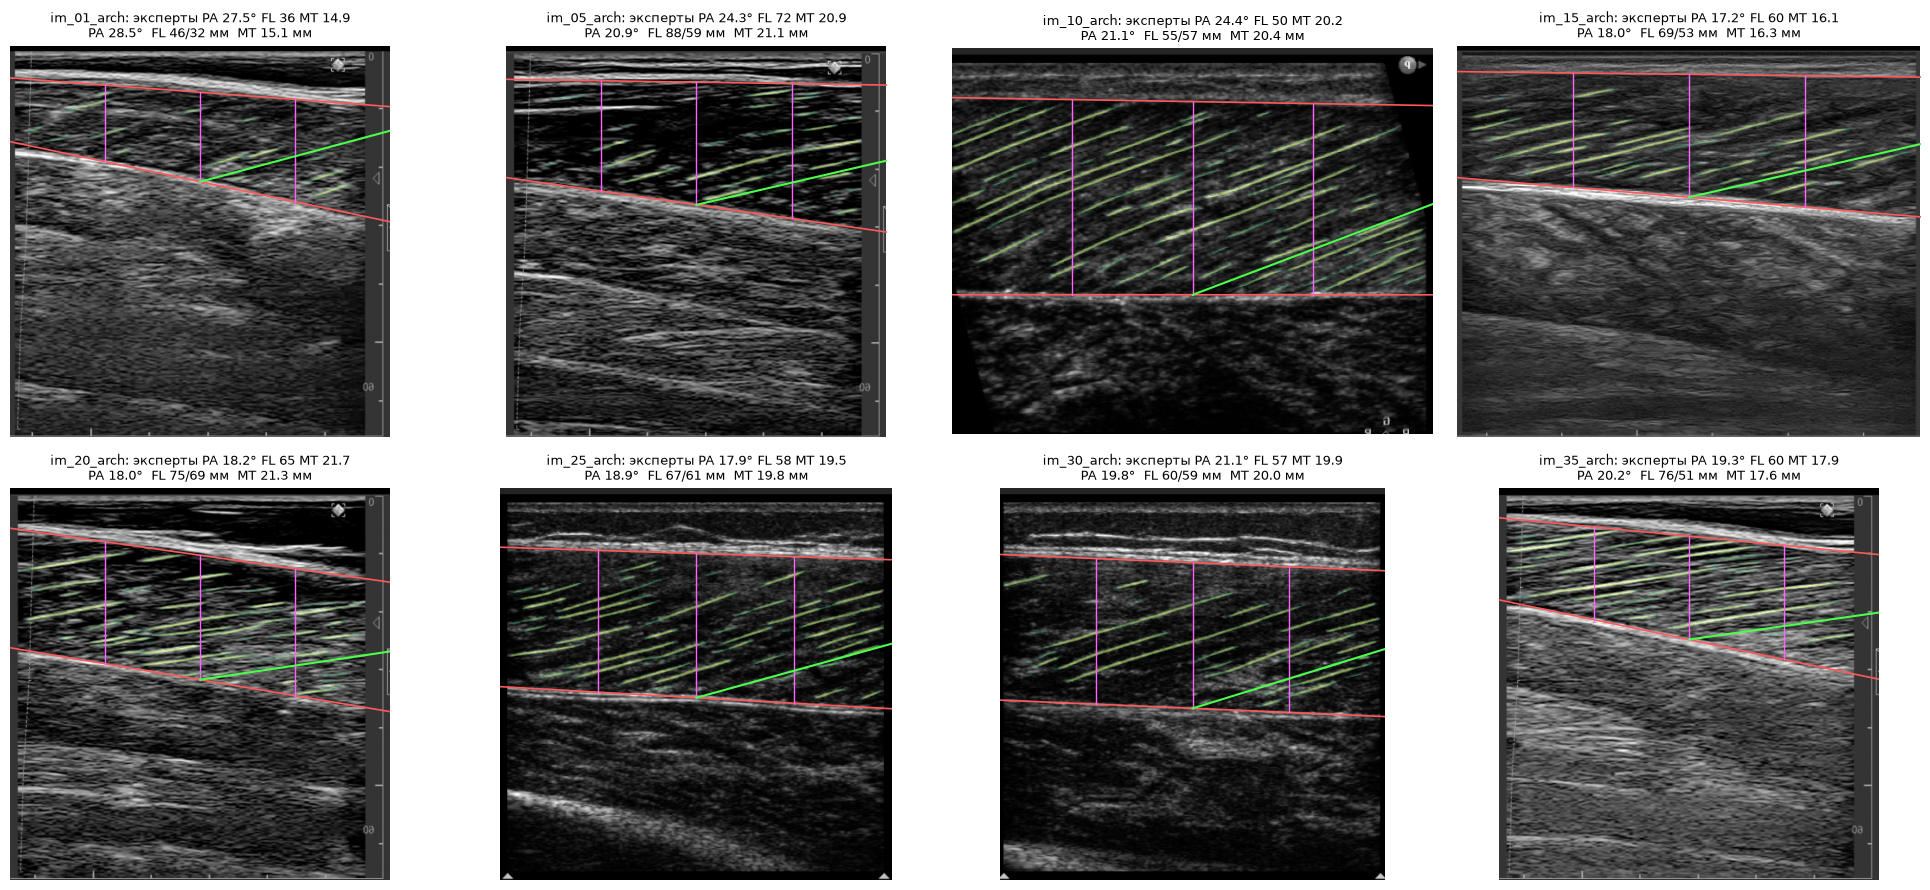

In [11]:
fig, axes = plt.subplots(2, 4, figsize=(20, 9))
for ax, i in zip(axes.ravel(), np.linspace(0, len(bench) - 1, 8).astype(int)):
    show_measure(bench_rois[i], bench_probs[i], bench.Scale_pixel_per_cm[i] / 10, ax=ax,
                 title=f"{bench.ImageID[i]}: эксперты PA {truth.pa[i]:.1f}° FL {truth.fl[i]:.0f} MT {truth.mt[i]:.1f}")
plt.tight_layout()
plt.show()

### Калибровка

Сырые оценки систематически сдвинуты относительно экспертов (у каждого эксперта свой сдвиг, у алгоритма тоже). Чиним минимумом параметров, чтобы не переобучиться на 35 снимках:

- FL = `w · fl_line + (1 − w) · fl_trig`, вес `w` из сетки;
- для каждого таргета одно из трёх: без поправки, сдвиг `y = x + c`, масштаб `y = s · x`. Параметр — медиана остатков (оптимум для MAE). Выбор по leave-one-out.

Поверх этого ручные ручки в `CFG`: `pa_offset`, `fl_scale` и `h_over_v`. Это гиперпараметры, которые разрешено проверять на публичном LB. Больше пары-тройки чисел так подбирать нельзя: публичная часть — всего ~100 снимков.

In [12]:
def combine_fl(df, w):
    fl = w * df.fl_line + (1 - w) * df.fl_trig
    return fl.fillna(df.fl_line).fillna(df.fl_trig)


def fit_correction(x: pd.Series, y: pd.Series, kind: str) -> float:
    if kind == "offset":
        return float(np.nanmedian(y - x))
    if kind == "scale":
        return float(np.nanmedian(y / x))
    return 0.0


def apply_correction(x, kind, p):
    return x + p if kind == "offset" else x * p if kind == "scale" else x


def loo_mae(x, y, kind):
    errs = []
    for i in range(len(x)):
        mask = np.arange(len(x)) != i
        errs.append(abs(apply_correction(x.iloc[i], kind, fit_correction(x[mask], y[mask], kind)) - y.iloc[i]))
    return np.nanmean(errs)


def choose_correction(x, y):
    loo = {kind: loo_mae(x, y, kind) for kind in ["none", "offset", "scale"]}
    kind = min(loo, key=loo.get)
    return (kind, fit_correction(x, y, kind)), loo


def fit_calibration(pred: pd.DataFrame, truth: pd.DataFrame):
    """PA and MT first, then FL from the corrected PA and MT (FL = MT / sin PA stays consistent)."""
    raw, calib, rows = pred.copy(), {}, []
    for t in ["pa", "mt", "fl"]:
        if t == "fl":
            raw["fl_trig"] = raw.mt / np.sin(np.radians(raw.pa))
            w = min(np.linspace(0, 1, 11), key=lambda w: (combine_fl(raw, w) - truth.fl).abs().mean())
            calib["fl_weight"] = float(w)
            raw["fl"] = combine_fl(raw, w)
        calib[t], loo = choose_correction(raw[t], truth[t])
        rows.append(dict(target=t, raw_mae=(raw[t] - truth[t]).abs().mean(),
                         **{f"loo_{k}": v for k, v in loo.items()}, chosen=calib[t][0], param=calib[t][1]))
        raw[t] = apply_correction(raw[t], *calib[t])
    return calib, pd.DataFrame(rows)


def apply_calibration(pred: pd.DataFrame, calib: dict) -> pd.DataFrame:
    out = pred.copy()
    out["pa"] = apply_correction(out.pa, *calib["pa"]) + CFG["pa_offset"]
    out["mt"] = apply_correction(out.mt, *calib["mt"])
    out["fl_trig"] = out.mt / np.sin(np.radians(out.pa))
    out["fl"] = apply_correction(combine_fl(out, calib["fl_weight"]), *calib["fl"]) * CFG["fl_scale"]
    return out


calib, table = fit_calibration(bench_pred, truth)
print(table.round(3).to_string(index=False))
print(f"вес fl_line: {calib['fl_weight']:.1f}")
print("\nсырые (FL = MT/sin PA):",
      {k: round(v, 3) for k, v in umud_score(bench_pred.assign(fl=bench_pred.fl_trig), truth).items()})
print("с калибровкой (in-sample):",
      {k: round(v, 3) for k, v in umud_score(apply_calibration(bench_pred, calib), truth).items()})
for r in raters + ["DLTrack"]:
    others = truth if r == "DLTrack" else pd.DataFrame(
        {t: bench[[f"{q}_{t.upper()}" for q in raters if q != r]].mean(axis=1) for t in TOL})
    single = pd.DataFrame({t: bench[f"{r}_{t.upper()}"] for t in TOL})
    print(f"  ориентир {r:8s}", round(umud_score(single, others)["score"], 3))
json.dump(calib, open(WORK / "calibration.json", "w"), indent=1)

target  raw_mae  loo_none  loo_offset  loo_scale chosen  param
    pa    1.069     1.069       1.082      1.081   none   0.00
    mt    0.466     0.466       0.468      0.466   none   0.00
    fl    3.535     3.535       3.276      3.056  scale   0.97
вес fl_line: 0.2

сырые (FL = MT/sin PA): {'score': np.float64(0.264), 'mae_pa': np.float64(1.069), 'mae_fl': np.float64(5.49), 'mae_mt': np.float64(0.466)}
с калибровкой (in-sample): {'score': np.float64(0.271), 'mae_pa': np.float64(1.66), 'mae_fl': np.float64(4.578), 'mae_mt': np.float64(0.466)}
  ориентир R1       0.264
  ориентир R2       0.296
  ориентир R3       0.25
  ориентир R4       0.326
  ориентир R5       0.258
  ориентир R6       0.246
  ориентир R7       0.483
  ориентир DLTrack  0.331


## 9. Тест и сабмит

Для каждого тестового кадра: рамка и масштаб из декодера, маски, геометрия, калибровка. Затем:
- медиана внутри 5-кадровых серий (кадры одного видео почти одинаковы);
- пропуски заполняются медианой по тесту;
- обрезка по диапазонам из описания данных.

In [13]:
def postprocess(df: pd.DataFrame, groups) -> pd.DataFrame:
    out = df.copy()
    out["group"] = groups
    for t in TOL:
        out[t] = out.groupby("group")[t].transform("median")
        out[t] = out[t].fillna(out[t].median())
    out["pa"], out["fl"], out["mt"] = out.pa.clip(5, 45), out.fl.clip(30, 200), out.mt.clip(10, 50)
    return out


def predict_test(test_probs: dict) -> pd.DataFrame:
    return pd.DataFrame([dict(image_id=r.image_id, layout=r.layout,
                              **measure(test_rois[r.image_id], test_probs[r.image_id], r.px_per_cm / 10,
                                        CFG["h_over_v"].get(r.layout, 1.0)))
                         for r in meta.itertuples()])


test_rois = {r.image_id: read_gray(r.path)[r.t:r.b, r.l:r.r] for r in meta.itertuples()}
test_groups = frame_groups(list(test_rois.values()))
test_probs = {k: all_probs(v) for k, v in test_rois.items()}
pickle.dump((test_rois, {k: v.astype(np.float16) for k, v in test_probs.items()}), open(WORK / "test_probs.pkl", "wb"))
test_pred = predict_test(test_probs)
print("геометрия не сошлась:", test_pred[["pa", "mt", "fl_trig"]].isna().any(axis=1).sum(), "из", len(test_pred))

sub = postprocess(apply_calibration(test_pred, calib), test_groups)
submission = sub.rename(columns={"pa": "pa_deg", "fl": "fl_mm", "mt": "mt_mm"})[["image_id", "pa_deg", "fl_mm", "mt_mm"]]
submission.to_csv(WORK / "submission_base.csv", index=False)   # раздел 10 пишет итоговый submission.csv
print(submission.describe().round(1))
print(sub.groupby("layout")[["pa", "fl", "mt"]].median().round(1))

геометрия не сошлась: 0 из 309
       pa_deg  fl_mm  mt_mm
count   309.0  309.0  309.0
mean     16.8   79.5   21.6
std       4.7   23.7    4.1
min       9.2   30.0   12.5
25%      13.6   62.1   18.6
50%      15.3   79.6   21.1
75%      19.2   91.1   25.0
max      38.5  148.3   34.0
                       pa     fl    mt
layout                                
bottom_ruler_513     20.1   54.2  17.2
bottom_ruler_853     20.0   53.1  15.7
lumify               21.6   55.6  19.6
siemens_right_ruler  17.2   76.1  20.8
telemed_644          14.1  105.2  25.9
telemed_left_ruler   13.7   89.9  22.4


In [14]:
# Test images are competition data: they are not displayed here, so that outputs can be published.

## 10. Обучаемая геометрия по ручной разметке теста

Хост разрешил использовать ручные замеры тестовых кадров для обучения и калибровки, если задекларировать их как внешние данные ([обсуждение](https://www.kaggle.com/competitions/umud-challenge-muscle-architecture-in-ultrasound-data/discussion/690868)). В `annotations/` лежит разметка всех 309 кадров: две точки на каждый апоневроз и одна фасцикула. PA, FL и MT пересчитываются из точек по нашей шкале (`umud_manual.py`): апоневрозы прямые, фасцикула продлевается до обоих.

Ручные формулы раздела 7 подбирались на 35 кадрах одной мышцы. Здесь их ошибку учит бустинг:
- признаки кадра из выхода сети: квантили углов фрагментов фасцикул (взвешены по длине), отдельно у глубокого и у поверхностного апоневроза, в центре и по краям; длины фрагментов; наклон и схождение апоневрозов; MT у краёв; сырые PA, FL, MT; масштаб и раскладка;
- ещё две независимые оценки PA: проекции карты фасцикул (Радон: при каком угле полосы самые контрастные) и фильтры Габора по самому снимку;
- FL как отрезок под углом PA через центр кадра между линиями апоневрозов, для каждой оценки PA. Ручной FL так и мерят; MT / sin PA ошибается там, где апоневрозы сходятся;
- цель: разница между разметкой и текущим ответом (для FL в логарифме), усреднённая по серии, чтобы снять шум разметчика;
- лосс MAE, неглубокие деревья.

Прогнозы перекрёстные: кадр всегда предсказывает модель, которая не видела ни одного кадра его серии. Так локальная оценка честная, а модель не повторяет ошибки разметчика на тех же кадрах.


In [15]:
def weighted_quantile(v, w, q):
    o = np.argsort(v)
    c = np.cumsum(np.asarray(w)[o])
    return float(np.asarray(v)[o][min(len(v) - 1, np.searchsorted(c, q * c[-1]))])


def fascicle_ray_length(sup, deep, t, W):
    """Length (px) of a straight fascicle at orientation t between the two aponeurosis lines,
    placed so that its middle is at the centre of the frame, as raters pick central fascicles."""
    (a1, b1), (a2, b2) = sup, deep
    ux, uy = np.cos(t), np.sin(t)
    if uy > 0:                                   # walk from the deep line up to the superficial one
        ux, uy = -ux, -uy
    den = uy - a1 * ux
    if abs(den) < 1e-6:
        return np.nan

    def climb(x0):
        y0 = a2 * x0 + b2
        return (a1 * x0 + b1 - y0) / den

    s = climb(W / 2)
    s = climb(W / 2 - s * ux / 2)
    return abs(s)


def band_mask(sup, deep, shape, lo=0.12, hi=0.88, x_lo=0.1, x_hi=0.9):
    H, W = shape
    yy, xx = np.mgrid[0:H, 0:W]
    y1, y2 = sup[0] * xx + sup[1], deep[0] * xx + deep[1]
    depth = (yy - y1) / np.maximum(y2 - y1, 1)
    return (depth > lo) & (depth < hi) & (xx > x_lo * W) & (xx < x_hi * W)


def candidate_orientations(t_deep, side, pas):
    return t_deep + side * np.radians(pas)


def pa_radon(p, band, t_deep, side, pas=np.arange(3, 40.5, 0.5)):
    """PA whose orientation makes the band-limited fascicle map most 'striped' (row-profile variance
    after rotating that orientation to horizontal), a projection (Radon) estimate."""
    H, W = p.shape
    c = (W / 2, H / 2)
    pm, m = (p * band).astype(np.float32), band.astype(np.float32)
    best, best_v = np.nan, -1.0
    for pa, t in zip(pas, candidate_orientations(t_deep, side, pas)):
        R = cv2.getRotationMatrix2D(c, np.degrees(t), 1.0)
        pr = cv2.warpAffine(pm, R, (W, H), flags=cv2.INTER_LINEAR)
        mr = cv2.warpAffine(m, R, (W, H), flags=cv2.INTER_LINEAR)
        cnt = mr.sum(axis=1)
        ok = cnt > 0.3 * cnt.max()
        if ok.sum() < 5:
            continue
        prof = pr.sum(axis=1)[ok] / cnt[ok]
        v = prof.var()
        if v > best_v:
            best, best_v = pa, v
    return best


def pa_gabor(g, band, t_deep, side, k, pas=np.arange(3, 41, 1.0)):
    """PA of the strongest oriented line texture of the raw image inside the band (Gabor filter bank)."""
    g = g.astype(np.float32) / 255
    best, best_e = np.nan, -1.0
    ks = int(6 * k) | 1
    for pa, t in zip(pas, candidate_orientations(t_deep, side, pas)):
        # cv2 theta is the direction across the stripes; the lines run along t
        kern = cv2.getGaborKernel((ks, ks), 1.2 * k, t + np.pi / 2, 2.0 * k, 0.5, 0)
        kern -= kern.mean()
        e = np.abs(cv2.filter2D(g, cv2.CV_32F, kern))[band].mean()
        if e > best_e:
            best, best_e = pa, e
    return best


def frame_features(rois: dict, probs: dict, meta: pd.DataFrame) -> pd.DataFrame:
    """Per-frame description of what the network found, for the learned correction."""
    k = CFG["px_per_mm"]
    rows = []
    for r in meta.itertuples():
        res, d = measure(rois[r.image_id], probs[r.image_id].astype(np.float32), r.px_per_cm / 10,
                         CFG["h_over_v"].get(r.layout, 1.0), return_debug=True)
        f = dict(image_id=r.image_id, px_per_cm=r.px_per_cm, depth_cm=r.depth_cm,
                 **{f"raw_{a}": b for a, b in res.items()})
        if d is not None:
            (a1, b1), (a2, b2) = d["sup"], d["deep"]
            W = d["gm"].shape[1]
            # FL as a centred straight fascicle between the two lines, for several PA estimates
            t_deep = np.arctan(a2)
            side = 1.0 if ((d["t_band"] - t_deep + np.pi / 2) % np.pi - np.pi / 2) > 0 else -1.0
            band = band_mask(d["sup"], d["deep"], d["gm"].shape)
            f["pa_radon"] = pa_radon(d["pm"][2], band, t_deep, side)
            f["pa_gabor"] = pa_gabor(d["gm"], band, t_deep, side, k)
            for name in ("pa", "pa_tensor", "pa_radon", "pa_gabor", "pa_orient"):
                v = f[name] if name.startswith("pa_r") or name.startswith("pa_g") else res[name]
                f[f"fl_ray_{name}"] = (fascicle_ray_length(d["sup"], d["deep"], t_deep + side * np.radians(v), W) / k
                                       if np.isfinite(v) and v > 1 else np.nan)
            f.update(sup_deg=np.degrees(np.arctan(a1)), deep_deg=np.degrees(np.arctan(a2)),
                     converge_deg=np.degrees(np.arctan(a2) - np.arctan(a1)), width_mm=W / k,
                     mt_left=perpendicular_mt(d["sup"], d["deep"], 0.1 * W) / k,
                     mt_right=perpendicular_mt(d["sup"], d["deep"], 0.9 * W) / k)
            segs = d["segs"]
            if len(segs) >= 3:
                pa = np.array([s[0] for s in segs])
                L = np.array([s[1] for s in segs]) / k
                x = np.array([s[2] for s in segs]) / W
                depth = np.array([(s[3] - (a1 * s[2] + b1)) / max(1, (a2 - a1) * s[2] + b2 - b1) for s in segs])
                f.update({f"pa_q{int(q * 100)}": weighted_quantile(pa, L, q) for q in (0.1, 0.25, 0.5, 0.75, 0.9)})
                f.update(seg_n=len(segs), seg_len_sum=L.sum(), seg_len_max=L.max(),
                         pa_std=np.sqrt(np.cov(pa, aweights=L)), pa_long=weighted_quantile(pa, L ** 3, 0.5))
                for name, m in (("deep", depth > 0.5), ("shallow", depth <= 0.5),
                                ("centre", (x > 0.3) & (x < 0.7)), ("edge", (x <= 0.3) | (x >= 0.7))):
                    f[f"pa_{name}"] = weighted_quantile(pa[m], L[m], 0.5) if m.sum() >= 2 else np.nan
                    f[f"len_{name}"] = L[m].sum()
        rows.append(f)
    return pd.DataFrame(rows)


def load_manual_labels(meta: pd.DataFrame) -> pd.DataFrame:
    """annotations/IMG_*.json -> PA, FL, MT in the hosts' convention (label_shift)."""
    sh, rows = CFG["learned"]["label_shift"], []
    box = meta.set_index(meta.image_id.str.split(".").str[0])
    for f in sorted((ROOT / CFG["learned"]["label_dir"]).glob("IMG_*.json")):
        d = json.loads(f.read_text(encoding="utf-8"))
        if not d.get("annotation_complete") or d["image_id"] not in box.index:
            continue
        pts = {k: [[p["x_px"], p["y_px"]] for p in v] for k, v in d["points"].items()}
        r = box.loc[d["image_id"]]
        fasc = pts.get("fascicle", [])
        m = measure_manual(dict(sup=pts["upper_aponeurosis"], deep=pts["lower_aponeurosis"],
                                fasc=[fasc[i:i + 2] for i in range(0, len(fasc) - 1, 2)]),
                           r.px_per_cm, (r.l, r.t, r.r, r.b))
        if np.isfinite(m["pa"]):
            rows.append(dict(image_id=r.image_id, pa=m["pa"] + sh["pa"], fl=m["fl"] * sh["fl"], mt=m["mt"] * sh["mt"]))
    return pd.DataFrame(rows)


def learned_correction(base: pd.DataFrame, feats: pd.DataFrame, labels: pd.DataFrame):
    """Cross-fitted residual model. Returns corrected pa, fl, mt for every frame of `base`."""
    d = base.merge(feats, on="image_id").merge(labels, on="image_id", how="left", suffixes=("", "_lab"))
    d["layout_code"] = d.layout.astype("category").cat.codes
    X_cols = [c for c in feats.columns if c != "image_id" and d[c].notna().any()] + ["layout_code", "pa", "fl", "mt"]
    has = d.pa_lab.notna().values
    lab_idx = np.flatnonzero(has)
    resid = {"pa": d.pa_lab - d.pa, "fl": np.log(d.fl_lab) - np.log(d.fl), "mt": d.mt_lab - d.mt}
    out, cfg = {}, CFG["learned"]
    for t, y in resid.items():
        y = y.groupby(d.group).transform("mean")            # series mean: less annotator noise
        pred = np.zeros(len(d))
        for seed in range(cfg["seeds"]):
            ids = d.group[has].unique()
            perm = dict(zip(ids, np.random.default_rng(seed).permutation(len(ids))))
            for tr, te in GroupKFold(cfg["n_splits"]).split(lab_idx, groups=d.group[has].map(perm)):
                m = HistGradientBoostingRegressor(loss="absolute_error", max_depth=3, learning_rate=0.05, max_iter=200,
                                                  min_samples_leaf=15, l2_regularization=1.0, random_state=seed,
                                                  categorical_features=[X_cols.index("layout_code")])
                m.fit(d.loc[lab_idx[tr], X_cols], y.iloc[lab_idx[tr]])
                pred[lab_idx[te]] += m.predict(d.loc[lab_idx[te], X_cols]) / cfg["seeds"]
                if (~has).any():                             # frames without a label: average of all models
                    pred[~has] += m.predict(d.loc[~has, X_cols]) / (cfg["seeds"] * cfg["n_splits"])
        out[t] = pd.Series(pred).groupby(d.group).transform("median").values
    new = d[["image_id", "layout", "group"]].copy()
    new["pa"], new["fl"], new["mt"] = d.pa + out["pa"], d.fl * np.exp(out["fl"]), d.mt + out["mt"]
    return new, d


if CFG["learned"]["enabled"] and (ROOT / CFG["learned"]["label_dir"]).exists():
    feats = frame_features(test_rois, test_probs, meta)
    labels = load_manual_labels(meta)
    learned, d = learned_correction(sub, feats, labels)
    learned["pa"], learned["fl"], learned["mt"] = learned.pa.clip(5, 45), learned.fl.clip(30, 200), learned.mt.clip(10, 50)
    lab = d.pa_lab.notna().values
    truth_lab = d.loc[lab, ["pa_lab", "fl_lab", "mt_lab"]].set_axis(["pa", "fl", "mt"], axis=1).reset_index(drop=True)
    for name, p in (("ручная геометрия", d), ("обучаемая", learned)):
        s = umud_score(p.loc[lab, ["pa", "fl", "mt"]].reset_index(drop=True), truth_lab)
        print(f"{name:17s} против разметки ({lab.sum()} кадров):", {k: round(v, 3) for k, v in s.items()})
    final = learned
else:
    final = sub
submission = final.rename(columns={"pa": "pa_deg", "fl": "fl_mm", "mt": "mt_mm"})[["image_id", "pa_deg", "fl_mm", "mt_mm"]]
submission.to_csv(WORK / "submission.csv", index=False)
print(final.groupby("layout")[["pa", "fl", "mt"]].median().round(1))


ручная геометрия  против разметки (309 кадров): {'score': np.float64(0.376), 'mae_pa': np.float64(1.412), 'mae_fl': np.float64(8.81), 'mae_mt': np.float64(0.472)}
обучаемая         против разметки (309 кадров): {'score': np.float64(0.32), 'mae_pa': np.float64(1.371), 'mae_fl': np.float64(7.171), 'mae_mt': np.float64(0.401)}
                       pa     fl    mt
layout                                
bottom_ruler_513     19.9   64.1  17.3
bottom_ruler_853     20.1   63.7  15.8
lumify               22.3   59.9  19.2
siemens_right_ruler  17.5   84.4  20.6
telemed_644          14.6  108.9  26.0
telemed_left_ruler   13.9   91.5  22.5
